In [1]:
#!/usr/bin/env python3

# PHY1063/PHY1073/PHY1078.  Implementation of a Monte Carlo transport code for criticality calculations.
# This code implements the Monte Carlo procedure discussed in the lectures for following
# a set of test particles to estimate the critical length.

# Evaluate command line arguments.  The default arguments run a calculation for a slab of Uranium 235,
# with the characteristic length (slab width) set equal to the exact (or at least, accurate to seven
# figures) value known from analytical calculations.  These analytical calculations are compiled in:
#
# A. Sood, R. A. Forster and D. K. Parsons, "Analytical benchmark test set for criticality code verification"
# Progress in Nuclear Energy 42(1), 55-106 (2003).
#
# This paper compiles a large set of exact solutions to criticality problems, some of them
# much more elaborate than the examples discussed here.
#
# The mayavi plotting package (the volume visualiser) appears not entirely straightforward to install,
# hence in this program, mayavi is disabled by default.  It can be enabled by a command line option.

In [2]:
import argparse

parser = argparse.ArgumentParser()
parser.add_argument( '--mayavi', help='Use mayavi'
                     ,default=False,action='store_true')
parser.add_argument( '--material', action = 'store', type = str
                     , help = 'Name of material.',default='u235')
parser.add_argument( '--shape', action = 'store', type = str
                     ,help = 'Name of shape.',default='slab')
parser.add_argument( '--length', action = 'store', type = float
                     , help = 'Characteristic length.',default=5.745868e-2)
parser.add_argument( '--paths', action = 'store', type = int
                     , help = 'Trajectories to sample',default=850000)
parser.add_argument( '--queue', action = 'store', type = int
                     , help = 'Queue length',default=15000)
args    = parser.parse_args([])  # Ignore Jupyter command-line arguments


In [3]:
from   collections       import deque
import matplotlib.pyplot as     plt
from   matplotlib        import rcParams
if args.mayavi:
    from mayavi          import mlab
import numpy
import random
from   scipy.optimize    import curve_fit
import sys

# Matplotlib parameters

rcParams.update({'figure.autolayout': True}) # Leave room for axis labels
plt_labsiz = 20                              # Axis label font size


In [4]:
def unit_vector():
    """Return a numpy array containing
       a random unit vector with three components.
    """
    u         = numpy.empty( 3 )
    cos_theta = 1.0 - 2.0*random.random()
    sin_theta = (1.0 - cos_theta**2.0)**0.5
    phi       = 2.0*numpy.pi*random.random()
    u[0]      = cos_theta
    u[1]      = sin_theta*numpy.cos( phi )
    u[2]      = sin_theta*numpy.sin( phi )
    return u


In [5]:
class exponential:
    """Fit an exponential to supplied data, and return the
       best fit coefficients and one standard deviation error.
    """
    @staticmethod
    def f( x , p0 , p1 ):
        return p0*numpy.exp( x*p1 )

    def fit( self , x , y ):
        p0 = [ y[0] , 0.0 ]
        p,cov=curve_fit(self.f,x,y,p0=p0)
        return p, numpy.sqrt( numpy.diag( cov ) )

class linear:
    """Fit an linear function to supplied data, and return the
       best fit coefficients and one standard deviation error.
    """
    @staticmethod
    def f( x , p0 , p1 ):
        return p0*(x*p1 + 1.0)

    def fit( self , x , y ):
        p0 = [ y[0] , 0.0 ]
        p,cov=curve_fit(self.f,x,y,p0=p0)
        return p, numpy.sqrt( numpy.diag( cov ) )


In [6]:
class shape():
    def __init__( self , length ):
        """Initialise the shape with the supplied characteristic length (which
           may be variously interpreted, e.g., the width of a slap, radius
           of a sphere, edge length of a cube.
        """
        pass
    def inside( self , r ):
        """r is a numpy array representing a vector position.  This function
           returns a logical value indicating whether this position is or
           is not in the shape.
        """
        return False
    def random_point( self ):
        """Return a random point within the shape.  These random points
           are supposed to be uniformly distributed within the volume.
        """
        pass
    def sample( self , r ):
        """r is a numpy array representing a vector position.  This function
           samples the volume distribution of test particles.
        """
        pass
    def plot_density( self , figure_index ):
        """Produce a plot of the volume sampled data."""
        pass


In [7]:
class slab(shape):
    """Class to implement the shape interface for a slab."""
    def __init__( self , width ):
        n_bins     = 100
        self.width = width
        self.bins  = numpy.zeros( n_bins )
        self.x     = numpy.arange( n_bins )*width/n_bins
    def inside( self , r ):
        if r[0] >= 0.0 and r[0] <= self.width:
            return True
        else:
            return False
    def random_point( self ):
        return [ random.random()*self.width , 0.0 , 0.0 ]
    def sample( self , r ):
        i = int( r[0]/self.width*len( self.bins ) )
        self.bins[i] += 1
    def plot_density( self , figure_index ):
        plt.figure( figure_index )
        plt.cla()
        plt.xlabel( r'$x$ ( cm )' , fontsize=plt_labsiz)
        plt.ylabel( r'Density ( au )' , fontsize=plt_labsiz)
        plt.tick_params(axis='both', which='major', labelsize=plt_labsiz)
        plt.plot( self.x , self.bins )
        plt.ylim( ymin=0 )


In [8]:
class cube(shape):
    """Class to implement the shape interface for a cube."""
    def __init__( self , edge ):
        n_bins     = 40
        self.edge  = edge
        self.bins  = numpy.zeros( ( n_bins , n_bins , n_bins ) )
        self.x     = numpy.arange( n_bins )*edge/n_bins
    def inside( self , r ):
        flag = True
        for i in range(3):
            if r[i] < 0.0 or r[i] > self.edge:
                flag = False
        return flag
    def random_point( self ):
        return self.edge*numpy.array( [ random.random() , random.random() , random.random() ] )
    def sample( self , r ):
        i = int( r[0]/self.edge*len( self.bins ) )
        j = int( r[1]/self.edge*len( self.bins ) )
        k = int( r[2]/self.edge*len( self.bins ) )
        self.bins[i,j,k] += 1
    def plot_density( self , figure_index ):
        if args.mayavi:
            # If we have the volume visualiser available, display
            # isosurfaces
            print( 'Update' )
            mlab.contour3d(self.bins, contours=4, transparent=True)
            mlab.outline()
            mlab.show()
            #yield
        else:
            # Otherwise, plot data along a line only
            plt.figure( figure_index )
            plt.cla()
            plt.xlabel( r'$z$ ( m )' , fontsize=plt_labsiz)
            plt.ylabel( r'Density ( au )' , fontsize=plt_labsiz)
            plt.tick_params(axis='both', which='major', labelsize=plt_labsiz)
            plt.plot( self.x , self.bins[len( self.bins )//2,len( self.bins )//2,:] )
            plt.ylim( ymin=0 )


In [9]:
class sphere(shape):
    """Class to implement the shape interface for a sphere."""
    def __init__( self , radius ):
        n_bins      = 40
        self.radius = radius
        self.bins   = numpy.zeros( n_bins )
        # Radial coordinates of the sampling bin boundaries
        self.r      = numpy.arange( n_bins + 1)*radius/(n_bins + 1)
        # Volumes corresponding to each sampling bin.  Note that for
        # Cartesian coordinate systems with a uniform bin size, all
        # the bins have the same volume, and if our density is
        # in arbitrary units, we need not worry at all about bin
        # volume.  However, for coordinate systems with a radial
        # axis, the bin volume varies with the radial coordinate,
        # which we must take into account in calculating the test
        # particle density.  In most cases, the density of test
        # particles near the origin is high, but the absolute number of
        # such particles is small.  So the computed density is noisy
        # near the origin.
        self.v      = (4.0/3.0)*numpy.pi*(self.r[1:]**3.0-self.r[0:-1]**3.0)
    def inside( self , r ):
        r2 = r[0]**2.0 + r[1]**2.0 + r[2]**2.0
        if r2 <= self.radius**2.0:
            return True
        else:
            return False
    def random_point( self ):
        while 1:
            r  = [1.0 - 2.0*random.random(), 1.0 - 2.0*random.random() , 1.0 - 2.0*random.random() ]
            r2 = r[0]**2.0 + r[1]**2.0 + r[2]**2.0
            if r2 <= 1.0:
                break
        return self.radius*numpy.array( r )
    def sample( self , r ):
        rr = (r[0]**2.0 + r[1]**2.0 + r[2]**2.0)**0.5
        i  = int( rr/self.radius*len( self.bins ) )
        self.bins[i] += 1
    def plot_density( self , figure_index ):
        plt.figure( figure_index )
        plt.cla()
        plt.xlabel( r'$r$ ( m )' , fontsize=plt_labsiz)
        plt.ylabel( r'Density ( au )' , fontsize=plt_labsiz)
        plt.tick_params(axis='both', which='major', labelsize=plt_labsiz)
        plt.plot( 0.5*(self.r[1:]+self.r[0:-1])
                  , self.bins/self.v )
        plt.ylim( ymin=0 )


In [10]:
class cylinder(shape):
    def __init__( self , radius ):
        self.radius = radius
        self.height = radius
        n_bins = 40
        self.bins   = numpy.zeros( n_bins )
        # Radial bin boundaries, from zero to the cylinder radius
        self.r = numpy.arange( n_bins + 1)*radius/(n_bins + 1)
        self.v = numpy.pi*self.height*(self.r[1:]**2.0 - self.r[:-1]**2.0)
    def inside( self , r ):
            r2 = r[0]**2.0 + r[1]**2.0
            if r2 <= self.radius**2.0 and abs(r[2]) <= self.radius/2.0:
                return True
            else:
                return False

    def random_point( self ):
        while 1:
            r  = [1.0 - 2.0*random.random(), 1.0 - 2.0*random.random(), 0.5 - random.random()]
            r2 = r[0]**2.0 + r[1]**2.0
            if r2 <= 1.0:
                break
        return self.radius*numpy.array( r )

    def sample( self , r ):
        rr = (r[0]**2.0 + r[1]**2.0)**0.5
        i  = int( rr/self.radius*len( self.bins ) )
        i  = min( i , len(self.bins) - 1 )
        self.bins[i] += 1

    def plot_density( self , figure_index ):
        plt.figure( figure_index )
        plt.cla()
        plt.xlabel( r'$r$ ( m )' , fontsize=plt_labsiz)
        plt.ylabel( r'Density ( au )' , fontsize=plt_labsiz)
        plt.tick_params(axis='both', which='major', labelsize=plt_labsiz)
        plt.plot( 0.5*(self.r[1:]+self.r[0:-1])
                  , self.bins/self.v )
        plt.ylim( ymin=0 )

    

In [11]:
def choose_shape( name , length ):
    if name == 'slab':
        return slab( length )
    elif name == 'cube':
        return cube( length )
    elif name == 'sphere':
        return sphere( length )
    elif name == 'cylinder':
        return cylinder( length )
    else:
        sys.stderr.write( 'Unknown shape: {}\n'.format( name ) )
        sys.exit( 1 )


In [12]:
class material:
    """Provides a function to update the position of a test particle
       by using a Monte Carlo procedure to follow one free path.  At the end
       of the path, either the test particle has left the volume, or a collision
       occurs.  If a collision occurs, and there is a fission event, new test
       particles are added to the queue that is passed as an argument.  If the
       test particle trajectory has not passed out of the volume and the test
       particle has not been captured in a collision, then the procedure
       returns False and the position of the test particle is updated.  Otherwise,
       the procedure returns True, and the test particle position has no
       significance.

       The coefficients needed in the Monte Carlo procedure are to be
       defined for particular materials in derived classes.
    """
    def scatter( self , x , queue , shape ):
        x          += unit_vector()*numpy.log( 1.0 - random.random() )/self.total
        ended       = False
        if not shape.inside( x ):
            ended = True
        else:
            p = random.random()
            if p > self.p_fission3:
                # Captured
                ended = True
            elif p > self.p_fission2:
                # Fission with 3 neutrons (two added)
                queue.appendleft( numpy.copy( x ) )
                queue.appendleft( numpy.copy( x ) )
            elif p > self.p_elastic:
                # Fission with 2 neutrons (one added)
                queue.appendleft( numpy.copy( x ) )
            else:
                # Elastic
                pass
        return ended


In [13]:
class pu239(material):
    """Monte Carlo scattering coefficients for Pu 239.  These data are
       from the first line of table 9 in Sood.  Note that there is an
       unusual convention here of supplying what are called "cross sections"
       [for which usual units are m**2] in m**(-1).  These are
       really the product of the density of nucleii and the cross
       section, or reciprocal mean free paths.
    """
    # Cross sections (in units of 1/meters)
    elastic    = 0.225216e2
    fission    = 0.081600e2
    capture    = 0.019584e2
    fission2   = 0.16*fission
    fission3   = 0.84*fission
    total      = elastic + fission + capture
    # Cumulative probabilities for various collision types
    p_elastic  = elastic/total
    p_fission2 = (elastic + fission2)/total
    p_fission3 = (elastic + fission2 + fission3)/total

class u235(material):
    """Monte Carlo scattering coefficients for U 235.  These data are
       from the second line of table 2 in Sood.
    """
    # Cross sections (in units of 1/meters)
    elastic    = 0.248064e2
    fission    = 0.065280e2
    capture    = 0.013056e2
    fission2   = 0.30*fission
    fission3   = 0.70*fission
    total      = elastic + fission + capture
    # Probabilities of various collision types
    p_elastic  = elastic/total
    p_fission2 = (elastic + fission2)/total
    p_fission3 = (elastic + fission2 + fission3)/total


In [14]:
def choose_material( name ):
    """Map from the material name supplied as a command line argument
       to the relevant implementation (or exit with an error message
       if there is no such implementation).
    """
    if name == 'u235':
        return u235()
    elif name == 'pu239':
        return pu239()
    else:
        sys.stderr.write( 'Unknown material: {}\n'.format( name ) )
        sys.exit( 1 )


In [15]:
shape                = choose_shape( args.shape , args.length )
stuff                = choose_material( args.material )
initial_queue_length = args.queue
maximum_paths        = args.paths


In [16]:
queue = deque()
for i in range(initial_queue_length):
    queue.appendleft( shape.random_point() )


In [17]:
# Choose a backend.  This has proved to be system/installation dependent.
# Other values (or none) might be more appropriate.
#plt.switch_backend( 'TkAgg' )
#plt.switch_backend( 'qt5Agg' )
plt.ion()
update_interval = 10000  # Gather data after this number of trajectories
path_counter    = 0      # Number of trajectories examined
queue_length    = []     # Number of test particles in queue (for plotting)
paths           = []     # Number of trajectories examined (for plotting)
grow            = []     # Growth rate (for plotting)
grow_err        = []     # Standard deviation of growth rate (for plotting)


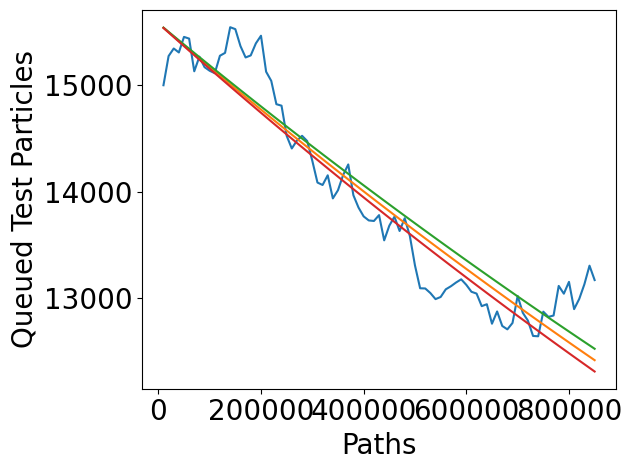

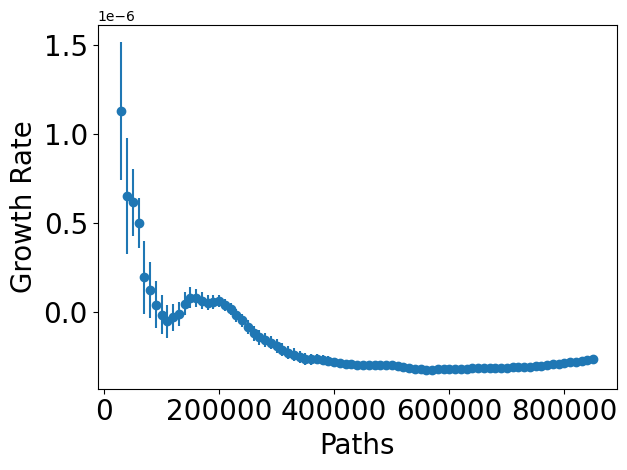

850000
850000
13098


In [18]:
#stop the plot from auto updating
plt.ioff()

while len( queue ) > 0 and path_counter < maximum_paths:
    # Get a new test particle from the queue
    r = queue.pop()
    # Follow the test particle to end of its trajectory
    while not stuff.scatter( r , queue , shape ):
        shape.sample( r )
    # At intervals, plot the progress of the calculation
    if path_counter%update_interval == 0:
        queue_length.append( len( queue ) )
        paths.append( len(queue_length)*update_interval )
        plt.figure( 1 )
        plt.cla()
        plt.tick_params(axis='both', which='major', labelsize=plt_labsiz)
        plt.plot( paths , numpy.array( queue_length ) )
        if len(paths) > 2:
            p , s = exponential().fit( paths, numpy.array( queue_length ) )
            grow.append( p[1] )
            grow_err.append( s[1] )
            if True:
                plt.plot( paths , p[0]*numpy.exp( p[1]*numpy.array( paths ) ) )
                plt.plot( paths , p[0]*numpy.exp( (p[1]+s[1])*numpy.array( paths ) ) )
                plt.plot( paths , p[0]*numpy.exp( (p[1]-s[1])*numpy.array( paths ) ) )
            else:
                plt.plot( paths , p[0]*(p[1]*numpy.array( paths ) + 1.0) )
                plt.plot( paths , p[0]*((p[1]+s[1])*numpy.array( paths ) + 1.0) )
                plt.plot( paths , p[0]*((p[1]-s[1])*numpy.array( paths ) + 1.0) )
            plt.xlabel( r'Paths' , fontsize=plt_labsiz)
            plt.ylabel( r'Queued Test Particles' , fontsize=plt_labsiz)
            plt.figure( 2 )
            plt.cla()
            plt.errorbar( paths[2:] , grow , yerr=grow_err , fmt='o' ) 
            plt.xlabel( r'Paths' , fontsize=plt_labsiz)
            plt.ylabel( r'Growth Rate' , fontsize=plt_labsiz)
            plt.tick_params(axis='both', which='major', labelsize=plt_labsiz)
    
    path_counter += 1
plt.show()

print(path_counter)
print(maximum_paths)
print(len(queue))


Stopped.  Maximum paths reached.


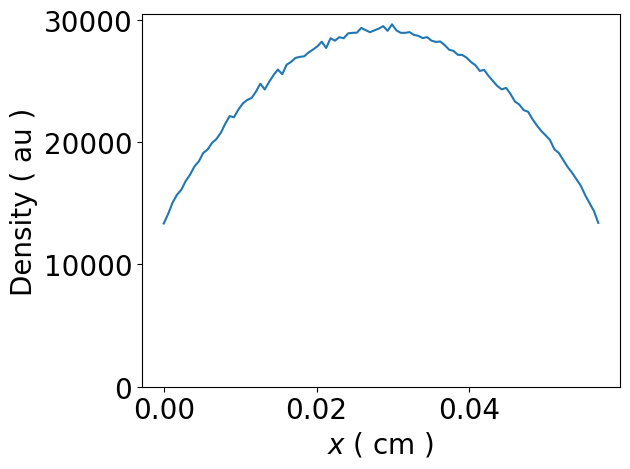

In [26]:
shape.plot_density( 3 )
if len( queue ) == 0:
    sys.stderr.write( 'Stopped.  Queue empty.\n' )
else:
    sys.stderr.write( 'Stopped.  Maximum paths reached.\n' )
sys.stderr.flush()   
plt.ioff()
plt.savefig("delete_soon.png", dpi = 50)
plt.show()


In [22]:
radii_cm = [8.88, 8.89, 9.0]

repeats = 20
initial_size = 1000
maximum_paths = 500000
update_interval = 1000

for radius in radii_cm:
    rates = []

    for run in range(repeats):
        test_shape = choose_shape("cylinder", radius / 100)
        stuff = choose_material("u235")

        queue = deque()
        for i in range(initial_size):
            queue.appendleft(test_shape.random_point())

        path_counter = 0
        paths = [0]
        queue_lengths = [initial_size]

        while len(queue) > 0 and path_counter < maximum_paths:
            r = queue.pop()

            while not stuff.scatter(r, queue, test_shape):
                test_shape.sample(r)

            path_counter += 1

            if path_counter % update_interval == 0 or len(queue) == 0 or path_counter == maximum_paths:
                paths.append(path_counter)
                queue_lengths.append(len(queue))

        x = numpy.array(paths) / path_counter
        y = numpy.array(queue_lengths)

        p, s = exponential().fit(x, y)
        rates.append(p[1] / path_counter)

    print(f"{numpy.mean(rates):.4e} {numpy.std(rates, ddof=1):.4e}")

-2.0329e-06 5.8762e-06


KeyboardInterrupt: 